# ch07_2. CNN → YOLO 연결 1단계 — 함수·main() 구조 정리본

## 함수 + `main()` 구조

기존 CNN(Classification, 분류)의 **무엇인가?**에 Bounding Box(바운딩 박스, 객체 위치)의 **어디인가?**를 추가한다.

```text
CNN Classification
        ↓
Single Object Localization
        ↓
Object Detection
        ↓
YOLO
```

이번 버전은 기능별 함수를 분리하고 마지막 `main()`이 전체 실행 순서를 관리한다.

```text
main()
 ├─ set_seed() / get_device()
 ├─ load_mnist()
 ├─ create_dataloaders()
 ├─ LocalizationCNN()
 ├─ train_model()
 │    └─ train_one_epoch()
 ├─ validate_model()
 └─ visualize_predictions()
```

In [15]:
# 01. 라이브러리 불러오기

import math
import random

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

## 1. 기본 설정 함수

- `set_seed()` : Random Seed 설정
- `get_device()` : GPU/CPU 선택

In [16]:
# 02. 기본 설정 함수

def set_seed(seed=42):
    # 실습 결과 비교를 위해 Random Seed를 고정
    random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def get_device():
    # CUDA 사용 가능 시 GPU, 아니면 CPU 사용
    return torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

## 2. MNIST 데이터 준비

원본 MNIST는 `Image + Label`을 제공한다. 이번 실습에서는 `LocalizedMNIST`가 여기에 Bounding Box 정답 `[cx, cy, w, h]`를 추가한다.

In [17]:
# 03. MNIST 불러오기 함수

def load_mnist(data_dir="./data"):
    mnist_train = datasets.MNIST(
        root=data_dir,
        train=True,
        download=True
    )

    mnist_test = datasets.MNIST(
        root=data_dir,
        train=False,
        download=True
    )

    return mnist_train, mnist_test

In [18]:
# 04. Single Object Localization용 Dataset

class LocalizedMNIST(Dataset):

    def __init__(
        self,
        base_dataset,
        canvas_size=64,
        random_position=True
    ):
        self.base_dataset = base_dataset
        self.canvas_size = canvas_size
        self.random_position = random_position
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, label = self.base_dataset[idx]
        digit = self.to_tensor(image)

        # 실제 숫자가 있는 픽셀 영역 찾기
        mask = digit[0] > 0.05
        ys, xs = torch.where(mask)

        y1 = ys.min().item()
        y2 = ys.max().item() + 1
        x1 = xs.min().item()
        x2 = xs.max().item() + 1

        # 숫자 주변 빈 공간 제거
        digit = digit[:, y1:y2, x1:x2]
        h = digit.shape[1]
        w = digit.shape[2]

        max_x = self.canvas_size - w
        max_y = self.canvas_size - h

        if self.random_position:
            x0 = random.randint(0, max_x)
            y0 = random.randint(0, max_y)
        else:
            # Validation은 같은 idx에서 항상 같은 위치
            generator = torch.Generator()
            generator.manual_seed(idx + 1000)

            x0 = torch.randint(
                0, max_x + 1, (1,), generator=generator
            ).item()

            y0 = torch.randint(
                0, max_y + 1, (1,), generator=generator
            ).item()

        # 64×64 캔버스 생성 후 숫자 삽입
        canvas = torch.zeros(
            1, self.canvas_size, self.canvas_size
        )

        canvas[:, y0:y0+h, x0:x0+w] = digit

        # YOLO와 연결되는 중심좌표 기반 Bounding Box
        cx = (x0 + w / 2) / self.canvas_size
        cy = (y0 + h / 2) / self.canvas_size
        bw = w / self.canvas_size
        bh = h / self.canvas_size

        bbox = torch.tensor(
            [cx, cy, bw, bh],
            dtype=torch.float32
        )

        return canvas, label, bbox

In [19]:
# 05. DataLoader 생성 함수

def create_dataloaders(
    mnist_train,
    mnist_test,
    batch_size=64,
    train_size=20000,
    val_size=5000,
    canvas_size=64,
    seed=42
):
    generator = torch.Generator().manual_seed(seed)

    train_indices = torch.randperm(
        len(mnist_train), generator=generator
    )[:train_size]

    val_indices = torch.arange(
        min(val_size, len(mnist_test))
    )

    train_base = Subset(mnist_train, train_indices)
    val_base = Subset(mnist_test, val_indices)

    train_dataset = LocalizedMNIST(
        train_base,
        canvas_size=canvas_size,
        random_position=True
    )

    val_dataset = LocalizedMNIST(
        val_base,
        canvas_size=canvas_size,
        random_position=False
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, val_loader


def inspect_dataloader(data_loader):
    images, labels, boxes = next(iter(data_loader))

    print("images :", images.shape)
    print("labels :", labels.shape)
    print("boxes  :", boxes.shape)

    return images, labels, boxes

예상 Shape:

```text
images → [64, 1, 64, 64]
labels → [64]
boxes  → [64, 4]
```

즉 한 이미지마다 `Class 정답 + Bounding Box 좌표 4개`가 존재한다.

## 3. Bounding Box 표시 함수

- 초록 실선 → 정답 Box
- 빨간 점선 → 예측 Box

검은 배경에서도 잘 보이도록 색을 명시한다.

In [20]:
# 06. Bounding Box 그리기

def draw_box(
    ax,
    box,
    canvas_size,
    label,
    edgecolor,
    linestyle="-"
):
    cx, cy, w, h = box.tolist()

    # 0~1 정규화 좌표 → Pixel 좌표
    cx *= canvas_size
    cy *= canvas_size
    w *= canvas_size
    h *= canvas_size

    x1 = cx - w / 2
    y1 = cy - h / 2

    rectangle = Rectangle(
        (x1, y1),
        w,
        h,
        fill=False,
        edgecolor=edgecolor,
        linewidth=2,
        linestyle=linestyle
    )

    ax.add_patch(rectangle)

    ax.text(
        x1,
        max(y1 - 1.5, 1),
        label,
        color=edgecolor,
        fontsize=9,
        bbox={
            "facecolor": "black",
            "alpha": 0.5,
            "pad": 1
        }
    )


def visualize_ground_truth(
    data_loader,
    canvas_size=64
):
    images, labels, boxes = next(iter(data_loader))

    image = images[0]
    label = labels[0]
    box = boxes[0]

    fig, ax = plt.subplots()
    ax.imshow(image.squeeze(), cmap="gray")

    draw_box(
        ax, box, canvas_size, "True",
        edgecolor="lime", linestyle="-"
    )

    ax.set_title(f"Class: {label.item()}")
    ax.axis("off")
    plt.show()

## 4. CNN 모델

하나의 CNN Feature에서 출력이 두 갈래로 나뉜다.

```text
             Shared Feature
                  │
         ┌────────┴────────┐
         ↓                 ↓
    Class Head          Box Head
         ↓                 ↓
      숫자 0~9        cx,cy,w,h
```

In [21]:
# 07. Localization CNN

class LocalizationCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.shared = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU()
        )

        # 무엇인가?
        self.class_head = nn.Linear(128, 10)

        # 어디에 있는가?
        self.box_head = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 4),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.features(x)
        feature = self.shared(x)

        class_logits = self.class_head(feature)
        pred_boxes = self.box_head(feature)

        return class_logits, pred_boxes


def inspect_model(model, data_loader, device):
    images, _, _ = next(iter(data_loader))
    images = images.to(device)

    model.eval()

    with torch.no_grad():
        class_logits, pred_boxes = model(images)

    print("class_logits:", class_logits.shape)
    print("pred_boxes  :", pred_boxes.shape)

Batch Size가 64이면:

```text
class_logits → [64, 10]
pred_boxes   → [64, 4]
```

## 5. Bounding Box 변환과 IoU

모델 출력 `[cx, cy, w, h]`를 IoU 계산용 `[x1, y1, x2, y2]`로 변환한다.

In [22]:
# 08. Bounding Box 변환 + IoU

def xywh_to_xyxy(boxes):
    cx = boxes[:, 0]
    cy = boxes[:, 1]
    w = boxes[:, 2]
    h = boxes[:, 3]

    x1 = cx - w / 2
    y1 = cy - h / 2
    x2 = cx + w / 2
    y2 = cy + h / 2

    return torch.stack(
        [x1, y1, x2, y2], dim=1
    )


def calculate_iou(pred_boxes, target_boxes):
    pred = xywh_to_xyxy(pred_boxes)
    target = xywh_to_xyxy(target_boxes)

    inter_x1 = torch.maximum(pred[:, 0], target[:, 0])
    inter_y1 = torch.maximum(pred[:, 1], target[:, 1])
    inter_x2 = torch.minimum(pred[:, 2], target[:, 2])
    inter_y2 = torch.minimum(pred[:, 3], target[:, 3])

    inter_w = (inter_x2 - inter_x1).clamp(min=0)
    inter_h = (inter_y2 - inter_y1).clamp(min=0)
    intersection = inter_w * inter_h

    pred_area = (
        (pred[:, 2] - pred[:, 0]).clamp(min=0)
        * (pred[:, 3] - pred[:, 1]).clamp(min=0)
    )

    target_area = (
        (target[:, 2] - target[:, 0]).clamp(min=0)
        * (target[:, 3] - target[:, 1]).clamp(min=0)
    )

    union = pred_area + target_area - intersection

    return intersection / (union + 1e-6)

## 6. Loss Function과 Optimizer

```text
Class → CrossEntropyLoss
Box   → SmoothL1Loss

Total Loss
→ Class Loss + BOX_WEIGHT × Box Loss
```

In [23]:
# 09. 학습 구성요소 생성 함수

def create_training_components(
    model,
    learning_rate=0.001
):
    class_loss_function = nn.CrossEntropyLoss()
    box_loss_function = nn.SmoothL1Loss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    return (
        class_loss_function,
        box_loss_function,
        optimizer
    )

## 7. 학습 함수

`train_one_epoch()`는 한 Epoch만 담당하고, `train_model()`은 Epoch 반복만 관리한다.

In [24]:
# 10. 한 Epoch 학습 함수

def train_one_epoch(
    model,
    data_loader,
    class_loss_function,
    box_loss_function,
    optimizer,
    device,
    box_weight=5.0
):
    model.train()

    loss_sum = 0.0
    class_loss_sum = 0.0
    box_loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels, boxes in data_loader:
        images = images.to(device)
        labels = labels.to(device)
        boxes = boxes.to(device)

        optimizer.zero_grad()

        class_logits, pred_boxes = model(images)

        class_loss = class_loss_function(
            class_logits, labels
        )

        box_loss = box_loss_function(
            pred_boxes, boxes
        )

        loss = class_loss + box_weight * box_loss

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        loss_sum += loss.item() * batch_size
        class_loss_sum += class_loss.item() * batch_size
        box_loss_sum += box_loss.item() * batch_size

        predictions = class_logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    return {
        "loss": loss_sum / total,
        "class_loss": class_loss_sum / total,
        "box_loss": box_loss_sum / total,
        "accuracy": correct / total
    }


def train_model(
    model,
    train_loader,
    class_loss_function,
    box_loss_function,
    optimizer,
    device,
    epochs=5,
    box_weight=5.0
):
    history = []

    for epoch in range(epochs):
        metrics = train_one_epoch(
            model,
            train_loader,
            class_loss_function,
            box_loss_function,
            optimizer,
            device,
            box_weight
        )

        history.append(metrics)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Total Loss: {metrics['loss']:.4f} | "
            f"Class Loss: {metrics['class_loss']:.4f} | "
            f"Box Loss: {metrics['box_loss']:.4f} | "
            f"Accuracy: {metrics['accuracy']:.4f}"
        )

    return history

## 8. Validation 함수

Classification은 Accuracy, 위치는 Mean IoU로 평가한다.

In [25]:
# 11. Validation 함수

def validate_model(model, data_loader, device):
    model.eval()

    correct = 0
    total = 0
    iou_sum = 0.0

    with torch.no_grad():
        for images, labels, boxes in data_loader:
            images = images.to(device)
            labels = labels.to(device)
            boxes = boxes.to(device)

            class_logits, pred_boxes = model(images)
            predictions = class_logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            iou = calculate_iou(pred_boxes, boxes)
            iou_sum += iou.sum().item()

    return {
        "accuracy": correct / total,
        "mean_iou": iou_sum / total
    }

## 9. 예측 + 3×3 Bounding Box 시각화

한 장이 아니라 9개 샘플을 한 번에 확인한다.

In [26]:
# 12. 예측 함수

def predict_sample(
    model,
    image,
    true_box,
    device
):
    model.eval()

    with torch.no_grad():
        class_logits, pred_boxes = model(
            image.unsqueeze(0).to(device)
        )

    pred_class = class_logits.argmax(dim=1).item()
    pred_box = pred_boxes[0].cpu()

    sample_iou = calculate_iou(
        pred_box.unsqueeze(0),
        true_box.unsqueeze(0)
    ).item()

    return pred_class, pred_box, sample_iou


def visualize_predictions(
    model,
    data_loader,
    device,
    canvas_size=64,
    num_samples=9
):
    images, labels, boxes = next(iter(data_loader))

    num_samples = min(num_samples, len(images))
    cols = 3
    rows = math.ceil(num_samples / cols)

    fig, axes = plt.subplots(
        rows, cols, figsize=(10, 3.3 * rows)
    )

    axes = axes.flatten()

    for index in range(num_samples):
        image = images[index]
        true_label = labels[index]
        true_box = boxes[index]

        pred_class, pred_box, sample_iou = predict_sample(
            model, image, true_box, device
        )

        ax = axes[index]
        ax.imshow(image.squeeze(), cmap="gray")

        # 정답 Box: 초록 실선
        draw_box(
            ax,
            true_box,
            canvas_size,
            "True",
            edgecolor="lime",
            linestyle="-"
        )

        # 예측 Box: 빨간 점선
        draw_box(
            ax,
            pred_box,
            canvas_size,
            "Pred",
            edgecolor="red",
            linestyle="--"
        )

        ax.set_title(
            f"True: {true_label.item()} | "
            f"Pred: {pred_class}\n"
            f"IoU: {sample_iou:.3f}"
        )

        ax.axis("off")

    for index in range(num_samples, len(axes)):
        axes[index].axis("off")

    plt.tight_layout()
    plt.show()

# 10. `main()` 함수

`main()`에서는 세부 계산을 직접 하지 않고, 앞에서 만든 함수들을 **순서대로 호출**한다.

In [27]:
# 13. main() 함수

def main():
    # -----------------------------
    # 1. Hyperparameter / 설정
    # -----------------------------
    SEED = 42
    BATCH_SIZE = 64
    TRAIN_SIZE = 20000
    VAL_SIZE = 5000
    CANVAS_SIZE = 64
    EPOCHS = 5
    LEARNING_RATE = 0.001
    BOX_WEIGHT = 5.0

    set_seed(SEED)
    device = get_device()

    print("Device:", device)

    # -----------------------------
    # 2. 데이터 준비
    # -----------------------------
    mnist_train, mnist_test = load_mnist()

    train_loader, val_loader = create_dataloaders(
        mnist_train, 
        mnist_test,
        batch_size=BATCH_SIZE,
        train_size=TRAIN_SIZE,
        val_size=VAL_SIZE,
        canvas_size=CANVAS_SIZE,
        seed=SEED
    )

    print("\n[Train Batch Shape]")
    inspect_dataloader(train_loader)

    # 학습 전에 Label Box가 맞는지 확인
    visualize_ground_truth(
        train_loader,
        canvas_size=CANVAS_SIZE
    )

    # -----------------------------
    # 3. 모델 생성
    # -----------------------------
    model = LocalizationCNN().to(device)

    print("\n[Model Output Shape]")
    inspect_model(model, train_loader, device)

    # -----------------------------
    # 4. Loss / Optimizer
    # -----------------------------
    (
        class_loss_function,
        box_loss_function,
        optimizer
    ) = create_training_components(
        model,
        learning_rate=LEARNING_RATE
    )

    # -----------------------------
    # 5. 학습
    # -----------------------------
    print("\n[Training]")

    history = train_model(
        model,
        train_loader,
        class_loss_function,
        box_loss_function,
        optimizer,
        device,
        epochs=EPOCHS,
        box_weight=BOX_WEIGHT
    )

    # -----------------------------
    # 6. Validation
    # -----------------------------
    print("\n[Validation]")

    val_metrics = validate_model(
        model, val_loader, device
    )

    print(
        "Validation Accuracy:",
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        "Mean IoU:",
        f"{val_metrics['mean_iou']:.4f}"
    )

    # -----------------------------
    # 7. 예측 Box 확인
    # -----------------------------
    visualize_predictions(
        model,
        val_loader,
        device,
        canvas_size=CANVAS_SIZE,
        num_samples=9
    )

    return model, history, val_metrics

## 11. 실행

위 셀들을 위에서 아래로 실행한 뒤 아래 셀을 실행한다.

Device: cuda

[Train Batch Shape]
images : torch.Size([64, 1, 64, 64])
labels : torch.Size([64])
boxes  : torch.Size([64, 4])


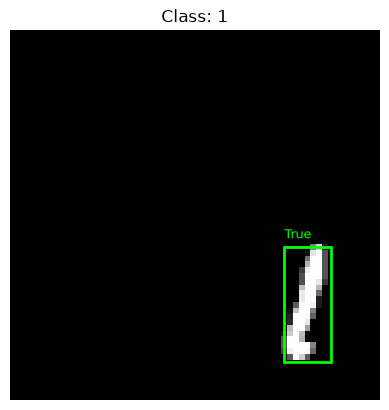


[Model Output Shape]
class_logits: torch.Size([64, 10])
pred_boxes  : torch.Size([64, 4])

[Training]
Epoch 1/5 | Total Loss: 1.6512 | Class Loss: 1.6326 | Box Loss: 0.0037 | Accuracy: 0.3955
Epoch 2/5 | Total Loss: 0.6131 | Class Loss: 0.6087 | Box Loss: 0.0009 | Accuracy: 0.8044
Epoch 3/5 | Total Loss: 0.3610 | Class Loss: 0.3576 | Box Loss: 0.0007 | Accuracy: 0.8893
Epoch 4/5 | Total Loss: 0.2697 | Class Loss: 0.2665 | Box Loss: 0.0006 | Accuracy: 0.9171
Epoch 5/5 | Total Loss: 0.2212 | Class Loss: 0.2182 | Box Loss: 0.0006 | Accuracy: 0.9324

[Validation]
Validation Accuracy: 0.9258
Mean IoU: 0.6579


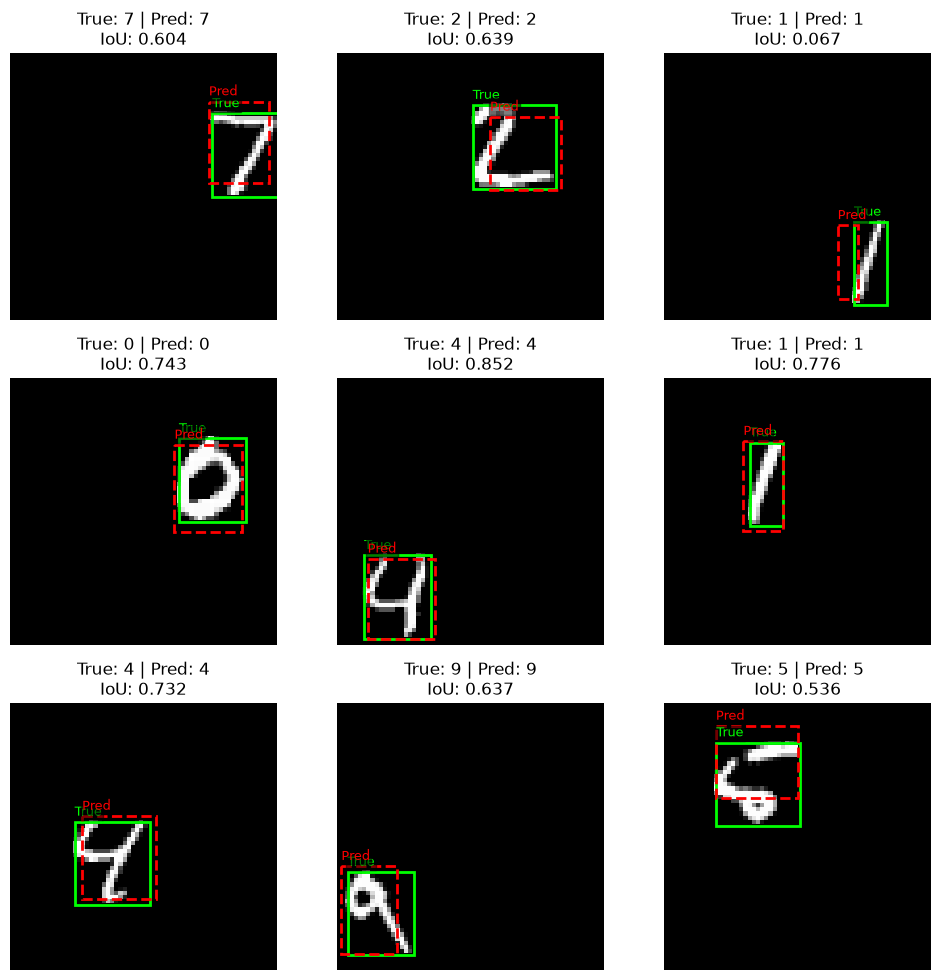

In [28]:
# 14. 프로그램 실행

if __name__ == "__main__":
    model, history, val_metrics = main()

# 최종 구조

```text
main()
 │
 ├─ set_seed()
 ├─ get_device()
 ├─ load_mnist()
 ├─ create_dataloaders()
 │    └─ LocalizedMNIST
 ├─ inspect_dataloader()
 ├─ visualize_ground_truth()
 ├─ LocalizationCNN()
 ├─ inspect_model()
 ├─ create_training_components()
 ├─ train_model()
 │    └─ train_one_epoch()
 ├─ validate_model()
 │    └─ calculate_iou()
 └─ visualize_predictions()
      ├─ predict_sample()
      └─ draw_box()
```

### CNN → YOLO 연결

```text
CNN
What?
 ↓
Single Object Localization
What + Where?
 ↓
Object Detection
여러 What + Where?
 ↓
YOLO
```

이번 구조에서는 다음 단계로 넘어갈 때 `Dataset`, `Model Head`, `Loss`, `Prediction` 부분을 확장하면 된다.